# 01 · Análisis exploratorio (EDA)

**Problema:** predecir `canceled_job`, es decir, si un trabajo de GPU reservado se cancela (1) o se completa (0).
**Métrica:** balanced accuracy.

**Reglas de este análisis**
- Se usa solo `train.csv`. El holdout `test.csv` no se mira.
- Cada paso tiene tres partes: qué muestran los datos, cómo lo interpretamos y qué decidimos.
- Las decisiones están resumidas en `reports/eda_decisiones.md` e implementadas en `src/compe/`.

**Pasos:** 1) estructura y calidad · 2) variable objetivo · 3) numéricas · 4) categóricas ·
5) relación con el objetivo · 6) relaciones entre variables · 7) conclusiones.

In [1]:
import itertools
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif

from compe import config as cfg
from compe.data import feature_groups, load_train
from compe.plots import (C_CANCEL, C_NEUTRAL, C_OK, C_SINL, C_TODO, INK2, plot_rate_dual,
                         rate_dual, save, set_style)

warnings.filterwarnings("ignore", category=FutureWarning)
set_style()
pd.set_option("display.max_columns", 50, "display.width", 200)

df = load_train()
y = df[cfg.TARGET]
LOCK = df["reservation_commitment"] == "locked_allocation"
sin = df[~LOCK]
print(f"train: {df.shape[0]:,} filas x {df.shape[1]} columnas".replace(",", "."))
print(f"Tasa de cancelación: {y.mean():.1%} en todo train | {sin[cfg.TARGET].mean():.1%} sin locked_allocation")
df.head(3)

train: 38.274 filas x 34 columnas
Tasa de cancelación: 41.7% en todo train | 30.6% sin locked_allocation


,canceled_job,hours_before_execution,execution_year,execution_month,execution_week,execution_day,peak_gpu_hours,offpeak_gpu_hours,num_primary_processes,num_auxiliary_processes,num_background_processes,service_tier,client_region,client_type,request_channel,returning_client,previous_job_cancellations,successful_previous_jobs,reserved_gpu_type,assigned_gpu_type,resource_modifications,reservation_commitment,orchestration_agent_id,organization_id,queue_wait_time,workload_profile,estimated_cost_per_hour,reserved_storage_units,special_resource_requests,execution_status,execution_status_date,total_processes,total_gpu_hours,high_value_client
0,0,6,2015,7,27,1,0,16,1,0.0,0,priority,PRT,managed_account,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,6.0,NaN,0,single_experiment,0.000,0,0,completed,2015-07-03,1.0,16,0
1,1,92,2015,7,27,1,16,32,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,2,canceled,2015-06-23,2.0,48,0
2,1,79,2015,7,27,2,0,24,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,1,canceled,2015-06-25,2.0,24,0


---
## Paso 1 · Estructura y calidad de los datos

In [2]:
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(2),
    "distintos": df.nunique(),
    "ejemplo": [df[c].dropna().iloc[0] for c in df.columns],
})
resumen

,tipo,nulos,pct_nulos,distintos,ejemplo
canceled_job,int64,0,0.00,2,0
hours_before_execution,int64,0,0.00,431,6
execution_year,int64,0,0.00,3,2015
execution_month,int64,0,0.00,12,7
execution_week,int64,0,0.00,53,27
execution_day,int64,0,0.00,31,1
peak_gpu_hours,int64,0,0.00,14,0
offpeak_gpu_hours,int64,0,0.00,27,16
num_primary_processes,int64,0,0.00,5,1
num_auxiliary_processes,float64,1,0.00,4,0.0


### 1.1 Nulos

In [3]:
nulos = resumen.loc[resumen.nulos > 0, ["nulos", "pct_nulos"]].sort_values("nulos", ascending=False)
display(nulos)
ag, org = df.orchestration_agent_id.notna(), df.organization_id.notna()
print(f"Con agente y organización: {(ag & org).sum()} | sin ninguno: {(~ag & ~org).sum():,}".replace(",", "."))

,nulos,pct_nulos
organization_id,36508,95.39
orchestration_agent_id,3945,10.31
client_region,19,0.05
num_auxiliary_processes,1,0.00


Con agente y organización: 27 | sin ninguno: 2.206


### 1.2 Duplicados

In [4]:
g_exact = df.groupby(list(df.columns), dropna=False, sort=False).ngroup()
copias = g_exact.map(g_exact.value_counts())
tramo = pd.cut(copias, [0, 1, 2, 5, 10, 50, 200], labels=["1 (sin repetir)", "2", "3 a 5", "6 a 10", "11 a 50", "51 a 180"])
dup = pd.DataFrame({
    "grupos": g_exact.groupby(tramo, observed=True).nunique(),
    "filas": tramo.value_counts().sort_index(),
    "tasa_cancelacion": df.groupby(tramo, observed=True)[cfg.TARGET].mean().round(3),
})
print(f"Filas que son copia exacta de otra: {df.duplicated().sum():,} ({df.duplicated().mean():.1%})".replace(",", "."))
display(dup)
cols_bloque = ["execution_year", "execution_month", "execution_day", "hours_before_execution",
               "client_type", "reservation_commitment", "execution_status_date", cfg.TARGET]
df.assign(copias=copias).drop_duplicates().nlargest(6, "copias")[["copias", *cols_bloque]]

Filas que son copia exacta de otra: 12.567 (32.8%)


,grupos,filas,tasa_cancelacion
1 (sin repetir),22927,22927,0.290
2,1631,3262,0.372
3 a 5,624,2260,0.385
6 a 10,219,1729,0.501
11 a 50,277,5945,0.737
51 a 180,29,2151,0.926


,copias,execution_year,execution_month,execution_day,hours_before_execution,client_type,reservation_commitment,execution_status_date,canceled_job
9660,180,2016,11,7,277,research_consortium,locked_allocation,2016-04-04,1
20411,150,2016,2,17,68,research_consortium,locked_allocation,2016-01-06,1
5385,101,2016,5,24,158,research_consortium,locked_allocation,2016-01-18,1
19223,100,2015,12,8,34,managed_account,locked_allocation,2015-11-17,1
9285,85,2016,11,1,166,managed_account,locked_allocation,2016-07-13,1
9413,85,2016,11,3,304,managed_account,locked_allocation,2016-02-01,1


In [5]:
g_feat = feature_groups(df)
por_grupo = df.groupby(g_feat)[cfg.TARGET].agg(n="size", tasa="mean")
mixtos = por_grupo[(por_grupo.tasa > 0) & (por_grupo.tasa < 1)]
minoria = (mixtos.n * np.minimum(mixtos.tasa, 1 - mixtos.tasa)).sum()
print(f"Grupos con las mismas variables de entrada y etiquetas distintas: {len(mixtos)} ({mixtos.n.sum()} filas)")
print(f"Filas imposibles de acertar por esa causa: {minoria:.0f} ({minoria / len(df):.2%} de train)")

Grupos con las mismas variables de entrada y etiquetas distintas: 52 (408 filas)
Filas imposibles de acertar por esa causa: 98 (0.26% de train)


### 1.3 Fuga de información

In [6]:
display(pd.crosstab(df["execution_status"], y))
fecha_exec = pd.to_datetime(dict(year=df.execution_year, month=df.execution_month, day=df.execution_day))
delta = (pd.to_datetime(df["execution_status_date"]) - fecha_exec).dt.days
duracion = df["total_gpu_hours"] // 8
regla_simple = (delta < 0).astype(int)
regla_fina = (delta != duracion).astype(int)
for nombre, r in [("fecha de estado anterior a la ejecución -> cancelado", regla_simple),
                  ("fecha de estado distinta de ejecución + duración -> cancelado", regla_fina)]:
    print(f"{nombre}: {(r != y).sum()} errores, acierto {(r == y).mean():.2%}")

canceled_job,0,1
execution_status,,
canceled,0,15536
completed,22310,0
no_show,0,428


fecha de estado anterior a la ejecución -> cancelado: 711 errores, acierto 98.14%
fecha de estado distinta de ejecución + duración -> cancelado: 15 errores, acierto 99.96%


**Qué muestran los datos**
- 38.274 filas y 34 columnas: 19 enteras, 5 decimales y 10 de texto. Los dos identificadores están guardados como decimales.
- Solo 4 columnas tienen nulos: `organization_id` (95,4%), `orchestration_agent_id` (10,3%), `client_region` (19 filas) y `num_auxiliary_processes` (1 fila).
- El 32,8% de las filas es copia exacta de otra. Cuanto más grande el grupo repetido, más cancela: 29% en las filas sin repetir y 93% en los grupos de más de 50 copias.
- `execution_status` coincide con el objetivo sin excepciones. Usando solo `execution_status_date` se acierta el 99,96%.

**Interpretación**
- Los nulos de los identificadores significan "sin agente" o "sin organización", no datos perdidos. Casi nunca se dan los dos juntos: son dos vías distintas de reservar.
- No hay identificador de reserva, así que dos reservas iguales son indistinguibles. Los grupos grandes son reservas en bloque: el mayor tiene 180 copias, reservadas y canceladas el mismo día.
- Hay 52 grupos con las mismas entradas y resultados distintos. Es ruido que ningún modelo puede resolver, pero afecta al 0,26% de las filas.

**Decisiones**
- Los nulos de los identificadores son una categoría propia (`sin_agente`, `sin_organizacion`); los de región, `region_desconocida`; el de procesos auxiliares, 0. No se descartan filas, porque el predictor tiene que responder por cada fila que reciba.
- Los duplicados se conservan. Para validar, las filas con las mismas entradas van siempre al mismo fold.
- `execution_status` y `execution_status_date` no entran a ningún modelo.

---
## Paso 2 · Variable objetivo

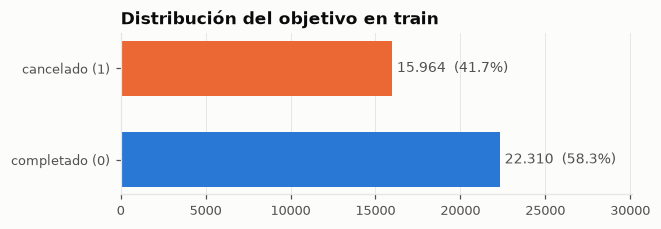

In [7]:
vc = y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 1.9))
ax.barh(["completado (0)", "cancelado (1)"], vc.values, color=[C_OK, C_CANCEL], height=0.6)
for i, v in enumerate(vc.values):
    ax.text(v + 300, i, f"{v:,}  ({v / len(df):.1%})".replace(",", "."), va="center", color=INK2)
ax.set_xlim(0, vc.max() * 1.35); ax.grid(axis="y", visible=False)
ax.set_title("Distribución del objetivo en train")
save(fig, "01_target"); plt.show()

In [8]:
repetida = copias > 1
subconjuntos = pd.DataFrame({
    "filas": [len(df), (~LOCK).sum(), (~repetida).sum(), repetida.sum()],
    "tasa_cancelacion": [y.mean(), y[~LOCK].mean(), y[~repetida].mean(), y[repetida].mean()],
}, index=["todo train", "sin locked_allocation", "filas sin repetir", "filas repetidas"]).round(3)
display(subconjuntos)
display(df.loc[y == 1, "execution_status"].value_counts().rename("filas de la clase 1").to_frame())

,filas,tasa_cancelacion
todo train,38274,0.417
sin locked_allocation,32126,0.306
filas sin repetir,22927,0.290
filas repetidas,15347,0.607


,filas de la clase 1
execution_status,
canceled,15536
no_show,428


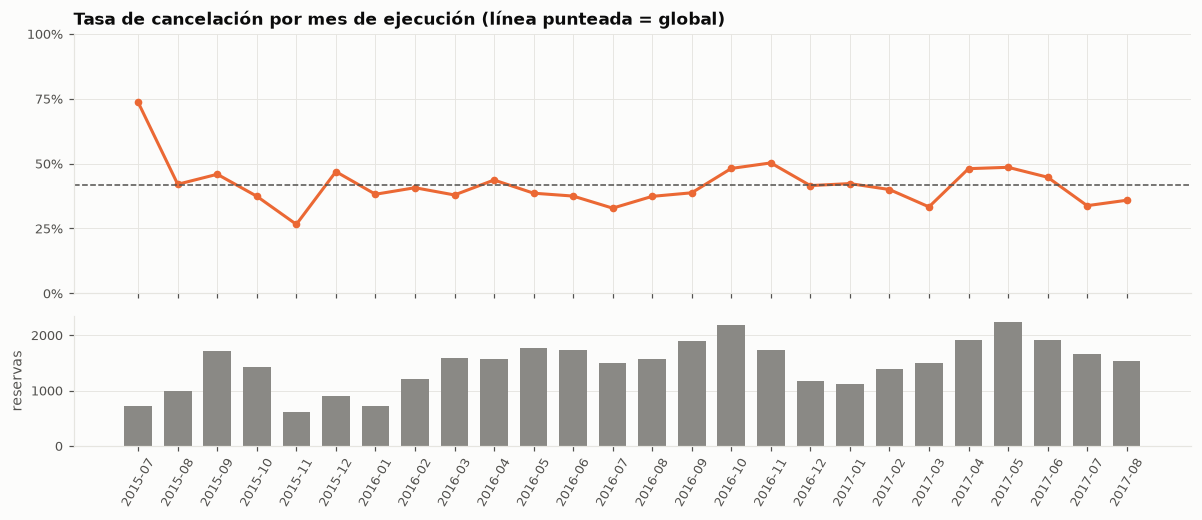

,filas,tasa
execution_year,,
2015,6393,0.448
2016,18654,0.408
2017,13227,0.415


In [9]:
mes = df.groupby(["execution_year", "execution_month"])[cfg.TARGET].agg(n="size", tasa="mean").reset_index()
etiquetas = [f"{a}-{m:02d}" for a, m in zip(mes.execution_year, mes.execution_month)]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 4.8), sharex=True, height_ratios=[2, 1])
a1.plot(etiquetas, mes.tasa, color=C_CANCEL, lw=2, marker="o", ms=4)
a1.axhline(y.mean(), color=INK2, lw=1, ls="--"); a1.set_ylim(0, 1)
a1.set_yticks(np.arange(0, 1.01, 0.25), [f"{v:.0%}" for v in np.arange(0, 1.01, 0.25)])
a1.set_title("Tasa de cancelación por mes de ejecución (línea punteada = global)")
a2.bar(etiquetas, mes.n, color=C_NEUTRAL, width=0.7); a2.set_ylabel("reservas"); a2.grid(axis="x", visible=False)
a2.tick_params(axis="x", rotation=60)
fig.tight_layout(); save(fig, "02_tiempo"); plt.show()
df.groupby("execution_year")[cfg.TARGET].agg(filas="size", tasa="mean").round(3)

**Qué muestran los datos**
- 58,3% completados y 41,7% cancelados: 1,4 completados por cada cancelado.
- La clase 1 junta dos situaciones: `canceled` (15.536, el cliente avisó) y `no_show` (428, no se presentó).
- La tasa depende mucho del subconjunto: 30,6% sin `locked_allocation` y 29% en las filas sin repetir.
- Es estable en el tiempo: entre 36% y 46% por mes, sin tendencia.

**Interpretación**
- El 41,7% global está inflado por las reservas en bloque. En una reserva común cancelan unos 3 de cada 10.
- La balanced accuracy promedia el porcentaje de cancelados detectados y el de completados detectados. Predecir siempre la misma clase da 50%, no 58%.

**Decisiones**
- No se rebalancean los datos; el desbalance es leve y se ajusta el punto de corte al modelar.
- Toda evaluación informa los dos porcentajes por separado además del promedio.

---
## Paso 3 · Variables numéricas

In [10]:
desc = df[cfg.NUM_COLS].describe(percentiles=[.5, .99]).T[["min", "50%", "mean", "99%", "max"]]
desc["pct_en_cero"] = (df[cfg.NUM_COLS] == 0).mean() * 100
desc["distintos"] = df[cfg.NUM_COLS].nunique()
desc.round(2).sort_values("pct_en_cero")

,min,50%,mean,99%,max,pct_en_cero,distintos
num_primary_processes,0.0,2.0,1.85,3.00,4.0,0.47,5
estimated_cost_per_hour,0.0,5.0,5.27,11.25,270.0,1.50,3646
hours_before_execution,0.0,75.0,110.39,457.00,629.0,3.92,431
offpeak_gpu_hours,0.0,16.0,17.51,48.00,328.0,6.35,27
peak_gpu_hours,0.0,8.0,6.39,16.00,128.0,47.54,14
special_resource_requests,0.0,0.0,0.55,3.00,5.0,60.12,6
resource_modifications,0.0,0.0,0.19,2.00,18.0,87.01,17
previous_job_cancellations,0.0,0.0,0.08,1.00,21.0,92.96,10
num_auxiliary_processes,0.0,0.0,0.09,2.00,3.0,93.55,4
queue_wait_time,0.0,0.0,2.97,87.00,391.0,95.84,94


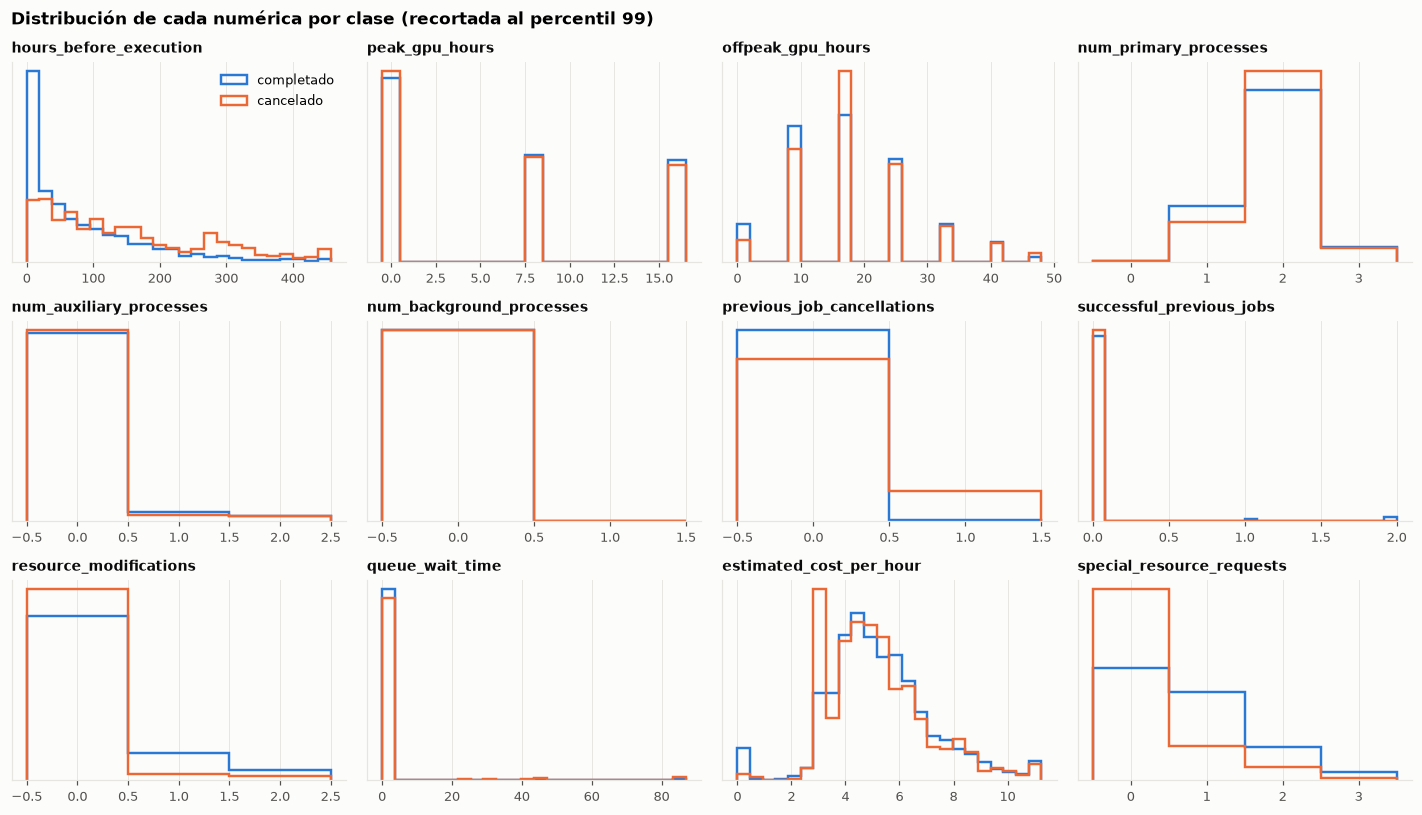

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(13, 7.5))
for ax, c in zip(axes.ravel(), cfg.NUM_COLS):
    hi = df[c].quantile(0.99)
    bins = np.linspace(0, max(hi, 1), 25) if df[c].nunique() > 25 else np.arange(-0.5, max(hi, 1) + 1.5, 1)
    for val, col, lab in [(0, C_OK, "completado"), (1, C_CANCEL, "cancelado")]:
        ax.hist(df.loc[y == val, c].clip(upper=hi), bins=bins, density=True, histtype="step", lw=1.6, color=col, label=lab)
    ax.set_title(c, fontsize=9); ax.set_yticks([])
axes[0, 0].legend()
fig.suptitle("Distribución de cada numérica por clase (recortada al percentil 99)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "03_numericas"); plt.show()

In [12]:
costo = df["estimated_cost_per_hour"]
vacias = (df["total_gpu_hours"] == 0) & (costo == 0)
print("Costos más altos:", sorted(costo)[-4:])
print(f"Costo 0: {(costo == 0).sum()} filas | 0 horas de GPU: {(df.total_gpu_hours == 0).sum()} | ambas: {vacias.sum()}")
print(f"Reservas vacías (0 horas y costo 0): {vacias.sum()} filas, cancelación {y[vacias].mean():.1%}")
print(f"0 procesos primarios: {(df.num_primary_processes == 0).sum()} | procesos de fondo > 2: {(df.num_background_processes > 2).sum()}")
print("previous_job_cancellations:", df.previous_job_cancellations.value_counts().sort_index().to_dict())

Costos más altos: [17.4815, 17.625, 18.6165, 270.0]
Costo 0: 574 filas | 0 horas de GPU: 157 | ambas: 157
Reservas vacías (0 horas y costo 0): 157 filas, cancelación 7.6%
0 procesos primarios: 181 | procesos de fondo > 2: 2
previous_job_cancellations: {0: 35581, 1: 2577, 2: 45, 3: 21, 4: 12, 5: 8, 6: 14, 11: 5, 13: 10, 21: 1}


**Qué muestran los datos**
- **Continuas con cola larga:** `hours_before_execution` (mediana 75, máximo 629) y `estimated_cost_per_hour` (mediana 5, concentrada entre 4 y 6,3).
- **Conteos con pocos valores:** las horas de GPU van de a 8; los procesos primarios son 2 en el 73% de las filas.
- **Casi siempre cero:** seis variables tienen entre 87% y 99,5% de ceros.
- **Rarezas:** un costo de 270 cuando el siguiente es 18,6; 574 filas con costo 0; 157 reservas con 0 horas de GPU y costo 0, que cancelan solo el 7,6%.

**Interpretación**
- Ninguna numérica es simétrica; casi todas se concentran en uno o dos valores.
- Los ceros de costo y de horas no son faltantes: describen un tipo de reserva (gratuita, de cortesía o de prueba).

**Decisiones**
- No se eliminan filas por valores extremos.
- El costo se recorta al percentil 99 de los datos de entrenamiento.
- Se agrega la columna `empty_job` para las reservas con 0 horas y costo 0.

---
## Paso 4 · Variables categóricas

In [13]:
frec = []
for c in cfg.CAT_COLS + cfg.BIN_COLS:
    vcn = df[c].value_counts(normalize=True)
    frec.append({"variable": c, "distintos": df[c].nunique(), "más común": vcn.index[0], "pct": round(vcn.iloc[0] * 100, 1),
                 "categorías con menos de 20 filas": int((df[c].value_counts() < 20).sum())})
pd.DataFrame(frec).set_index("variable")

,distintos,más común,pct,categorías con menos de 20 filas
variable,,,,
service_tier,4,standard,78.3,1
client_region,143,PRT,38.6,89
client_type,8,cloud_marketplace,48.9,1
request_channel,5,broker_platform,87.4,1
reserved_gpu_type,8,GPU_T1,78.7,2
assigned_gpu_type,9,GPU_T1,71.5,1
reservation_commitment,3,no_commitment,83.9,1
workload_profile,4,single_experiment,74.8,0
returning_client,2,0,97.6,0


In [14]:
alta = []
for c in ["client_region", "orchestration_agent_id", "organization_id"]:
    n = df[c].value_counts()
    alta.append({"variable": c, "distintos": len(n), "pct_nulos": round(df[c].isna().mean() * 100, 1),
                 "pct de la mayor": round(n.iloc[0] / len(df) * 100, 1),
                 "pct que cubren las 10 mayores (no nulos)": round(n.head(10).sum() / n.sum() * 100, 1),
                 "con menos de 20 filas": int((n < 20).sum()), "con 1 fila": int((n == 1).sum())})
display(pd.DataFrame(alta).set_index("variable"))
print("Coincidencia entre GPU reservada y asignada:", f"{(df.reserved_gpu_type == df.assigned_gpu_type).mean():.1%}")
print("independent_client que entra por api_direct:",
      f"{(df.loc[df.client_type == 'independent_client', 'request_channel'] == 'api_direct').mean():.1%}")
df[df.client_region.isin(["CN", "CHN", "CAN"])].groupby("client_region").agg(
    filas=(cfg.TARGET, "size"), tasa=(cfg.TARGET, "mean"), anticipacion_mediana=("hours_before_execution", "median")).round(3)

,distintos,pct_nulos,pct de la mayor,pct que cubren las 10 mayores (no nulos),con menos de 20 filas,con 1 fila
variable,,,,,,
client_region,143,0.0,38.6,82.9,89,27
orchestration_agent_id,185,10.3,40.4,78.2,112,33
organization_id,159,95.4,1.1,56.8,142,64


Coincidencia entre GPU reservada y asignada: 90.9%
independent_client que entra por api_direct: 99.4%


,filas,tasa,anticipacion_mediana
client_region,,,
CHN,448,0.525,31.0
CN,234,0.350,81.0


**Qué muestran los datos**
- Todas las categóricas tienen una categoría dominante (entre 49% y 87% de las filas) y varias casi vacías.
- Región, agente y organización tienen entre 143 y 185 valores con cola muy larga: decenas de categorías con menos de 20 filas.
- Existen los códigos `CN` y `CHN`, con perfiles distintos (35% y 52,5% de cancelación), y ningún `CAN`.

**Interpretación**
- Con pocas filas no se puede saber nada confiable de una categoría; un modelo que las memorice sobreajusta.
- El test va a traer regiones, agentes y organizaciones que no vimos.

**Decisiones**
- Toda categoría con menos de 20 filas pasa a `otros`, igual que las que aparezcan por primera vez al predecir. El conteo se hace solo con los datos de entrenamiento de cada fold.
- No se unifican ni corrigen códigos de región por suposición: `CN` y `CHN` quedan separados.
- Las categóricas se codifican dentro del pipeline (`compe.pipeline`).

---
## Paso 5 · Relación de cada variable con el objetivo

Cada relación se lee dos veces: sobre **todo train** (referencia 41,7%) y **sin `locked_allocation`** (referencia 30,6%).
Las 6.148 reservas `locked_allocation` cancelan el 99,8% y hacen que otras variables parezcan más fuertes de lo que son.

In [15]:
rate_dual(df, "reservation_commitment")

,filas,tasa,filas_sin_locked,tasa_sin_locked
reservation_commitment,,,,
no_commitment,32116,0.306,32116,0.306
locked_allocation,6148,0.998,0,NaN
flexible_commitment,10,0.700,10,0.700


### 5.1 Numéricas

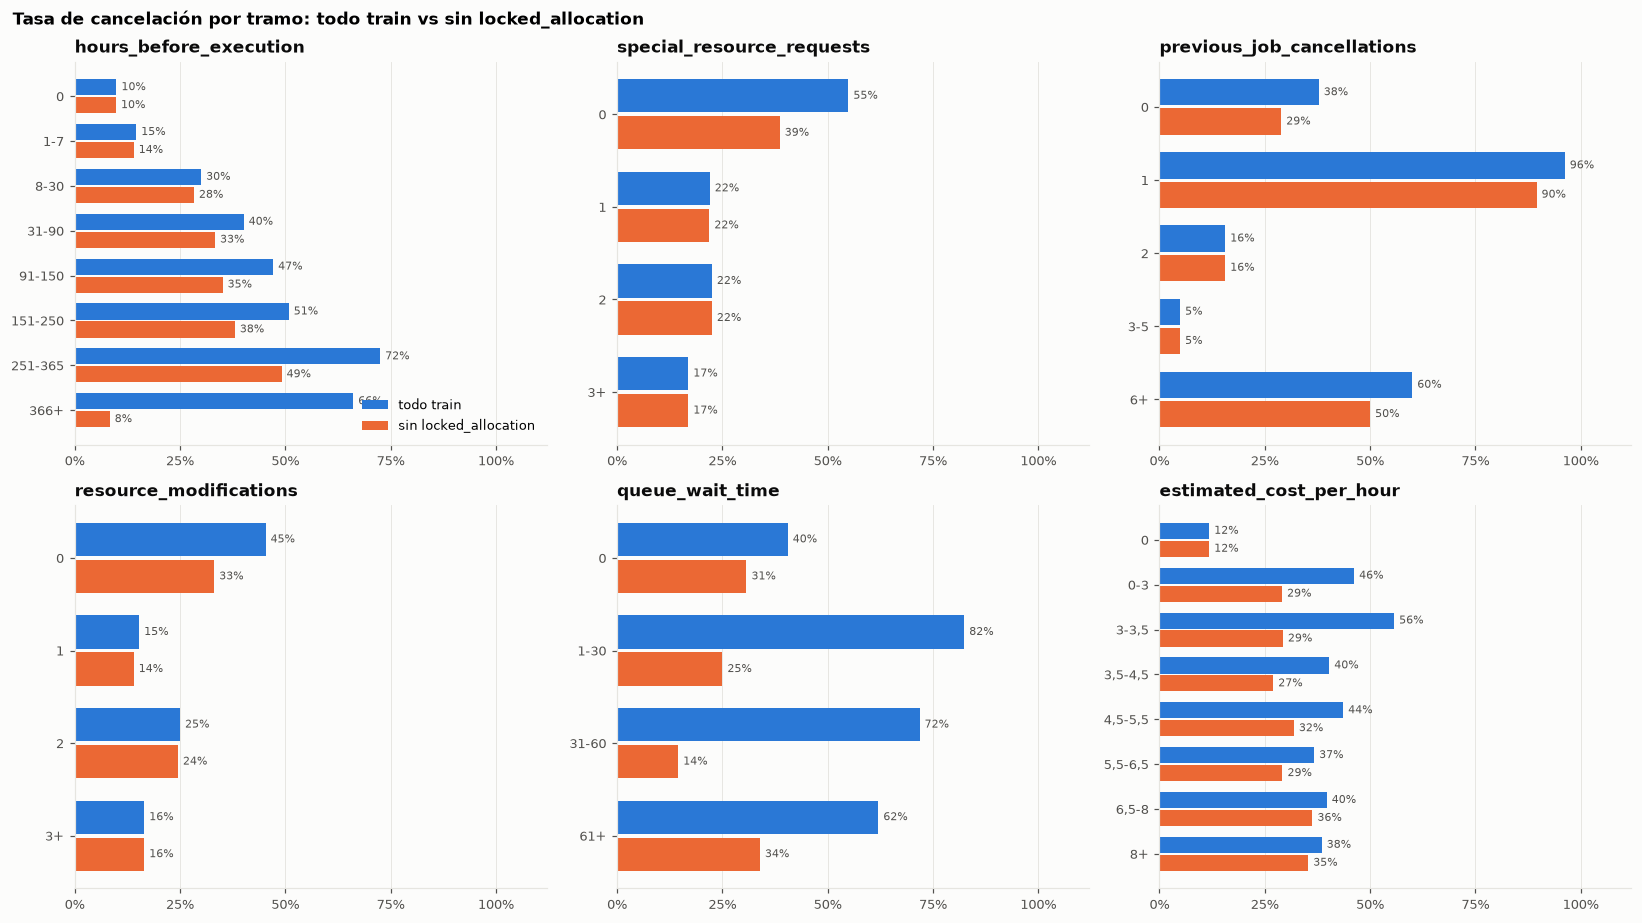

In [16]:
BINS = {
    "hours_before_execution": ([-1, 0, 7, 30, 90, 150, 250, 365, 700], ["0", "1-7", "8-30", "31-90", "91-150", "151-250", "251-365", "366+"]),
    "special_resource_requests": ([-1, 0, 1, 2, 9], ["0", "1", "2", "3+"]),
    "previous_job_cancellations": ([-1, 0, 1, 2, 5, 30], ["0", "1", "2", "3-5", "6+"]),
    "resource_modifications": ([-1, 0, 1, 2, 30], ["0", "1", "2", "3+"]),
    "queue_wait_time": ([-1, 0, 30, 60, 400], ["0", "1-30", "31-60", "61+"]),
    "estimated_cost_per_hour": ([-1, 0, 3, 3.5, 4.5, 5.5, 6.5, 8, 300], ["0", "0-3", "3-3,5", "3,5-4,5", "4,5-5,5", "5,5-6,5", "6,5-8", "8+"]),
}
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (c, (b, l)) in zip(axes.ravel(), BINS.items()):
    plot_rate_dual(df, c, bins=b, labels=l, ax=ax)
axes[0, 0].legend(loc="lower right")
fig.suptitle("Tasa de cancelación por tramo: todo train vs sin locked_allocation", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "04_numericas_vs_objetivo"); plt.show()

In [17]:
for c in ["hours_before_execution", "previous_job_cancellations", "queue_wait_time"]:
    display(rate_dual(df, c, *BINS[c]).rename_axis(c))

,filas,tasa,filas_sin_locked,tasa_sin_locked
hours_before_execution,,,,
0,1499,0.099,1498,0.098
1-7,3721,0.146,3691,0.140
8-30,6003,0.300,5861,0.283
31-90,9858,0.401,8847,0.333
91-150,6472,0.471,5272,0.351
151-250,5571,0.508,4417,0.380
251-365,3726,0.725,2013,0.491
366+,1424,0.661,527,0.083


,filas,tasa,filas_sin_locked,tasa_sin_locked
previous_job_cancellations,,,,
0,35581,0.378,31091,0.289
1,2577,0.962,925,0.895
2,45,0.156,45,0.156
3-5,41,0.049,41,0.049
6+,30,0.600,24,0.500


,filas,tasa,filas_sin_locked,tasa_sin_locked
queue_wait_time,,,,
0,36680,0.405,31490,0.307
1-30,295,0.824,68,0.250
31-60,730,0.718,241,0.145
61+,569,0.620,327,0.339


In [18]:
otras = {
    "successful_previous_jobs": ([-1, 0, 100], ["0", "1+"]),
    "offpeak_gpu_hours": ([-1, 0, 16, 40, 400], ["0", "8-16", "24-40", "48+"]),
    "peak_gpu_hours": ([-1, 0, 16, 200], ["0", "8-16", "24+"]),
    "num_primary_processes": ([-1, 0, 1, 2, 9], ["0", "1", "2", "3+"]),
    "num_background_processes": ([-1, 0, 20], ["0", "1+"]),
}
pd.concat({c: rate_dual(df, c, b, l) for c, (b, l) in otras.items()})

filas   tasa  filas_sin_locked  tasa_sin_locked
successful_previous_jobs 0      37531  0.424             31388            0.311
                         1+       743  0.073               738            0.072
offpeak_gpu_hours        0       2431  0.291              2209            0.220
                         8-16   22881  0.434             18308            0.293
                         24-40  12427  0.404             11074            0.331
                         48+      535  0.581               535            0.581
peak_gpu_hours           0      18196  0.425             14438            0.276
                         8-16   19697  0.406             17307            0.325
                         24+      381  0.572               381            0.572
num_primary_processes    0        181  0.265               181            0.265
                         1       7701  0.337              6524            0.218
                         2      28081  0.443             23115            0.323
                         3+      2311  0.388              2306            0.387
num_background_processes 0      38098  0.418             31950            0.307
                         1+       176  0.176               176            0.176

**Qué muestran los datos**
- **Señal fuerte:** anticipación (de 10% a 49% sin `locked_allocation`), pedidos especiales (39% sin pedidos, 22% con uno), cancelaciones previas (90% con exactamente una) y modificaciones (33% sin tocar la reserva, 14% con una).
- **Señal media o débil:** trabajos exitosos previos, horas de GPU, cantidad de procesos. El costo es casi plano salvo el costo 0 (12%).
- **Dos espejismos:** `queue_wait_time` parece disparar la cancelación (82% con 1 a 30 de espera) y el costo tiene un pico en 3–3,5 (56%). Sin `locked_allocation` ambos desaparecen (25% y 29%).

**Interpretación**
- Varias relaciones no son rectas: la anticipación cae a 8% por encima de 365, y las cancelaciones previas pasan de 90% (una) a 16% (dos).
- En las variables casi siempre cero no alcanza con un indicador "mayor que cero": en cancelaciones previas, 1 y 2 son opuestos.

**Decisiones**
- Las numéricas se usan con su valor original, sin indicadores ni tramos.
- Se conservan `total_gpu_hours` y `total_processes`: la cancelación sube con la duración total.
- Se conserva `queue_wait_time` aunque su señal propia sea casi nula.

### 5.2 Categóricas

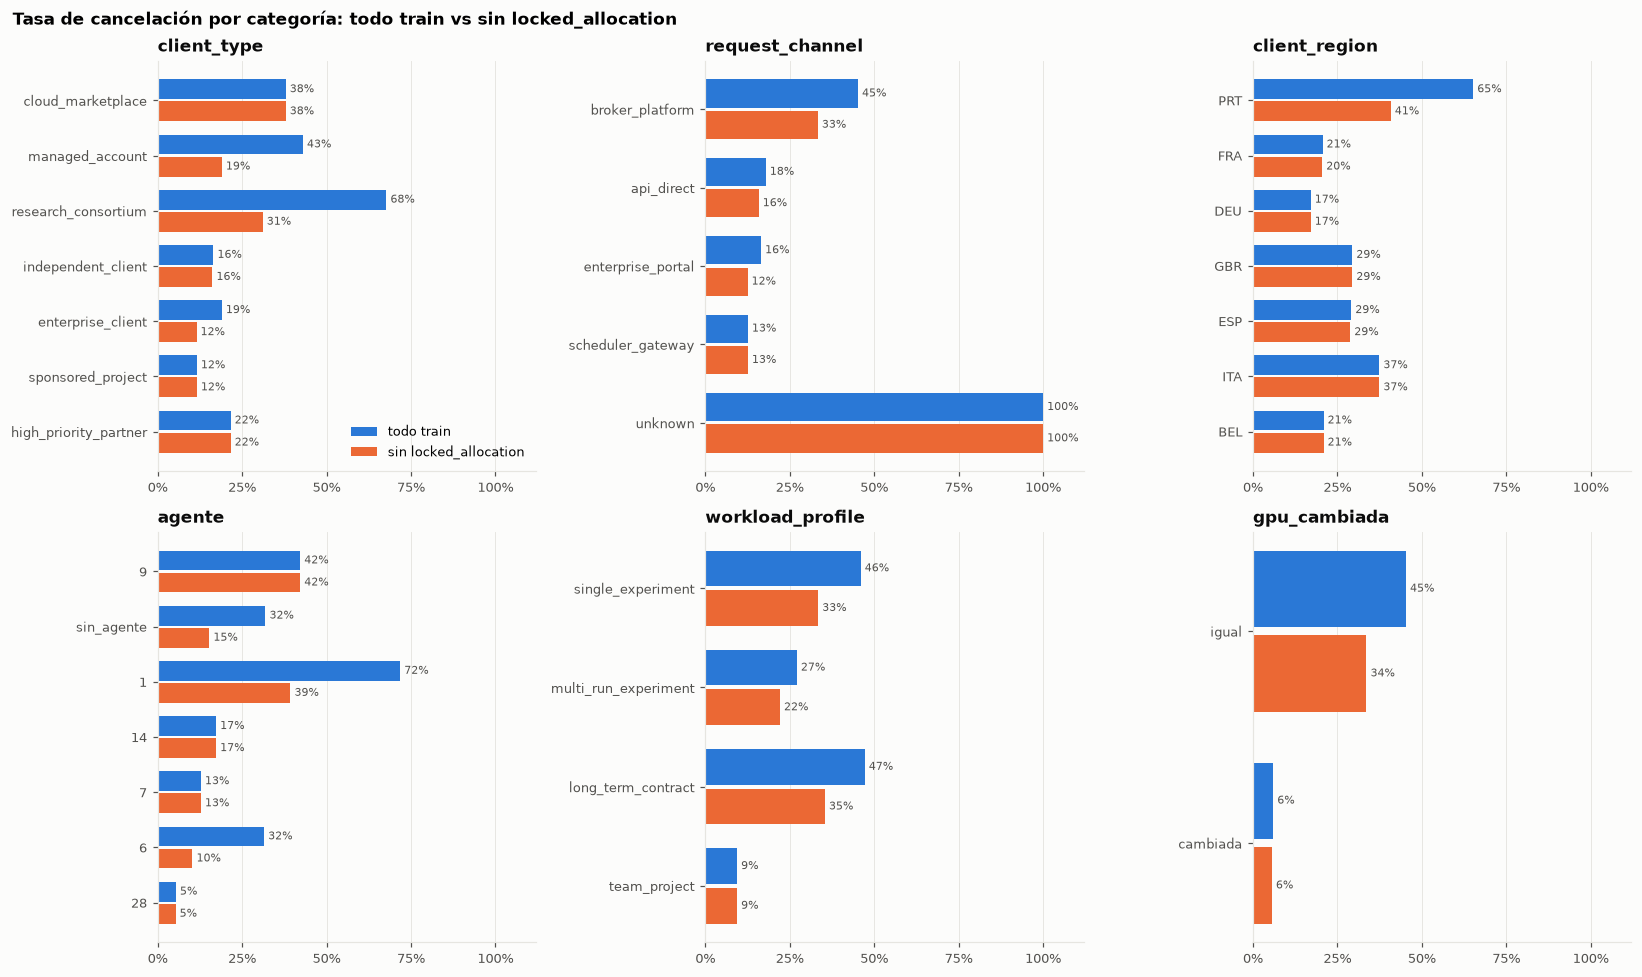

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
d5 = df.assign(gpu_cambiada=np.where(df.reserved_gpu_type != df.assigned_gpu_type, "cambiada", "igual"),
               agente=df.orchestration_agent_id.astype("Int64").astype("string").fillna("sin_agente").astype(object))
for ax, c in zip(axes.ravel(), ["client_type", "request_channel", "client_region", "agente", "workload_profile", "gpu_cambiada"]):
    plot_rate_dual(d5, c, top=7, ax=ax)
axes[0, 0].legend(loc="lower right")
fig.suptitle("Tasa de cancelación por categoría: todo train vs sin locked_allocation", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "05_categoricas_vs_objetivo"); plt.show()

In [20]:
display(rate_dual(df, "client_type"))
pd.concat({c: rate_dual(df, c) for c in ["reserved_storage_units", "returning_client", "high_value_client", "service_tier"]})

,filas,tasa,filas_sin_locked,tasa_sin_locked
client_type,,,,
cloud_marketplace,18717,0.379,18710,0.379
managed_account,8306,0.430,5839,0.190
research_consortium,6655,0.677,3116,0.311
independent_client,2896,0.165,2884,0.162
enterprise_client,1350,0.190,1227,0.115
sponsored_project,233,0.116,233,0.116
high_priority_partner,116,0.216,116,0.216
unknown,1,1.000,1,1.000


filas   tasa  filas_sin_locked  tasa_sin_locked
reserved_storage_units 0           37358  0.427             31210            0.315
                       1             916  0.000               916            0.000
returning_client       0           37370  0.423             31245            0.310
                       1             904  0.171               881            0.151
high_value_client      0           29289  0.435             23680            0.301
                       1            8985  0.359              8446            0.319
service_tier           standard    29973  0.428             24429            0.299
                       basic        5081  0.383              5077            0.383
                       priority     3211  0.368              2611            0.223
                       enterprise      9  0.556                 9            0.556

In [21]:
def dispersion(col, minimo):
    t = sin.groupby(col)[cfg.TARGET].agg(["size", "mean"])
    t = t[t["size"] >= minimo]["mean"]
    return {"categorías": len(t), "tasa mínima": t.min(), "mediana": t.median(), "tasa máxima": t.max()}

display(pd.DataFrame({"client_region (50+ filas)": dispersion("client_region", 50),
                      "orchestration_agent_id (50+ filas)": dispersion("orchestration_agent_id", 50),
                      "organization_id (20+ filas)": dispersion("organization_id", 20)}).T.round(2))
sin.groupby(sin.organization_id.notna().map({True: "con organización", False: "sin organización"}))[cfg.TARGET].agg(filas="size", tasa="mean").round(3)

,categorías,tasa mínima,mediana,tasa máxima
client_region (50+ filas),37.0,0.01,0.29,0.55
orchestration_agent_id (50+ filas),43.0,0.00,0.17,0.84
organization_id (20+ filas),14.0,0.02,0.11,0.40


,filas,tasa
organization_id,,
con organización,1573,0.111
sin organización,30553,0.316


**Qué muestran los datos**
- **Tipo de cliente:** `research_consortium` parece el que más cancela (68%), pero sin `locked_allocation` queda en 31%. El que más cancela de verdad es `cloud_marketplace` (38%); los clientes directos y corporativos, entre 12% y 16%.
- **Canal:** por intermediario (`broker_platform`) cancela 33%; por canales directos, entre 13% y 16%.
- **Región y agente:** son las de mayor dispersión. Entre agentes con 50 o más filas la tasa va de 0% a 84%.
- **Almacenamiento reservado:** las 916 reservas que lo tienen no se cancelaron nunca.
- **GPU cambiada:** 6% de cancelación contra 34%, también sin `locked_allocation`.
- **Organización:** con organización cancelan 11% contra 32%.
- **`high_value_client`:** casi sin señal (32% contra 30%).

**Decisiones**
- Para la organización se usan el indicador `has_organization` y el identificador agrupado.
- Ninguna regla se fija a mano (por ejemplo, almacenamiento reservado): la aprende el modelo.
- `assigned_gpu_type` y GPU cambiada se evalúan en los dos casos, con y sin (ver 5.3).

### 5.3 Los `no_show` y la GPU asignada

In [22]:
d53 = df.assign(gpu_cambiada=df.reserved_gpu_type != df.assigned_gpu_type, repetida=repetida)
perfil = d53.groupby("execution_status").agg(
    filas=(cfg.TARGET, "size"),
    anticipacion_mediana=("hours_before_execution", "median"),
    sin_pedidos_especiales=("special_resource_requests", lambda s: (s == 0).mean()),
    sin_modificaciones=("resource_modifications", lambda s: (s == 0).mean()),
    una_cancelacion_previa=("previous_job_cancellations", lambda s: (s == 1).mean()),
    locked_allocation=("reservation_commitment", lambda s: (s == "locked_allocation").mean()),
    canal_broker=("request_channel", lambda s: (s == "broker_platform").mean()),
    gpu_cambiada=("gpu_cambiada", "mean"),
    fila_repetida=("repetida", "mean"),
    region_PRT=("client_region", lambda s: (s == "PRT").mean()),
    con_almacenamiento=("reserved_storage_units", "mean"),
).T.round(3)
perfil[["canceled", "no_show", "completed"]]

execution_status,canceled,no_show,completed
filas,15536.000,428.000,22310.000
anticipacion_mediana,120.000,28.000,49.000
sin_pedidos_especiales,0.798,0.540,0.465
sin_modificaciones,0.948,0.862,0.816
una_cancelacion_previa,0.160,0.002,0.004
locked_allocation,0.395,0.002,0.001
canal_broker,0.952,0.773,0.821
gpu_cambiada,0.010,0.140,0.146
fila_repetida,0.594,0.210,0.270
region_PRT,0.605,0.523,0.230


**Qué muestran los datos**
- Los 428 `no_show` tienen perfil de completados: poca anticipación (mediana 28), pedidos especiales, sin bloques ni cancelaciones previas. Solo la región `PRT` y la falta de almacenamiento los acercan a los cancelados.
- La GPU cambiada aparece en el 15% de los completados y el 14% de los `no_show`, contra el 1% de los `canceled`.

**Interpretación**
- Al predecir no se sabe qué reservas son `no_show`, y por sus datos parecen completadas. Es un límite: como máximo cuestan cerca de 1,3 puntos de balanced accuracy.
- La reasignación de GPU ocurre cerca del día de ejecución, sobre las reservas que siguen vigentes. La variable indica "seguía viva ese día", no intención de cancelar: se registra tarde.

**Decisiones**
- Sin tratamiento especial para los `no_show`; la evaluación informa aparte qué porcentaje se detecta.
- Todo modelo se evalúa con y sin `assigned_gpu_type`, y se declara en la presentación.

### 5.4 Ranking de señal

Información mutua de cada variable con el objetivo: mide cuánto reduce la incertidumbre, sin suponer una relación recta.

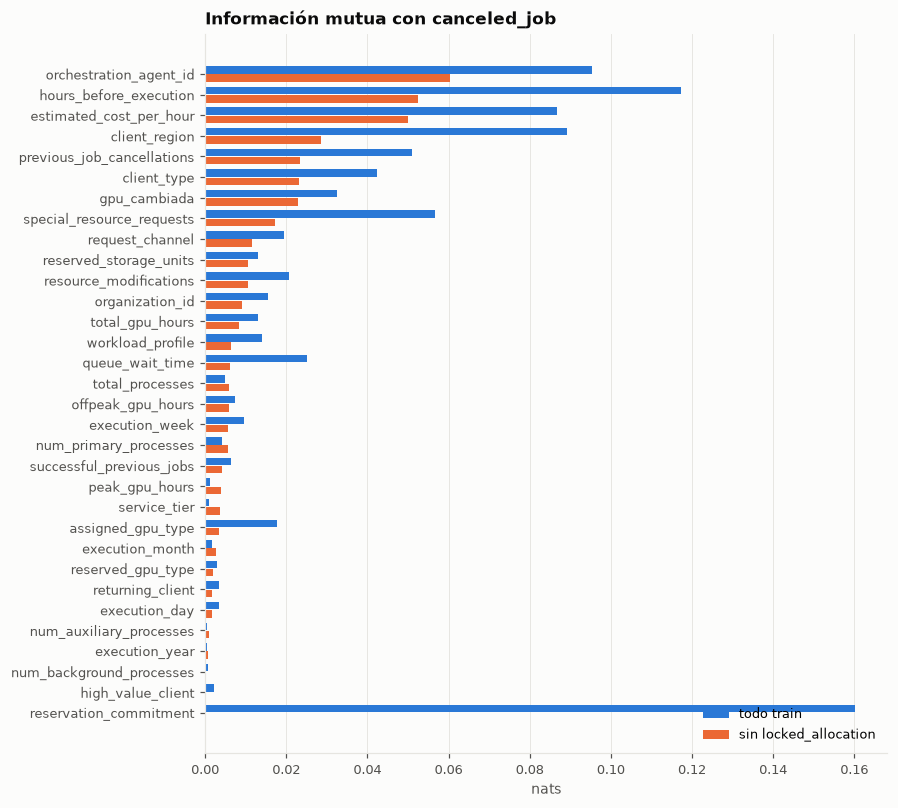

In [23]:
X = df[cfg.FEATURE_COLS].copy()
X["gpu_cambiada"] = (df.reserved_gpu_type != df.assigned_gpu_type).astype(int)
for c in cfg.CAT_COLS + cfg.ID_COLS:
    X[c] = X[c].astype("object").where(X[c].notna(), "(nulo)").astype("category").cat.codes
X = X.fillna(-1)
discretas = [c != "estimated_cost_per_hour" for c in X.columns]
mi = pd.DataFrame({
    "todo train": mutual_info_classif(X, y, discrete_features=discretas, random_state=cfg.SEED),
    "sin locked_allocation": mutual_info_classif(X[~LOCK], y[~LOCK], discrete_features=discretas, random_state=cfg.SEED),
}, index=X.columns).sort_values("sin locked_allocation")
fig, ax = plt.subplots(figsize=(8, 8.5))
yy = np.arange(len(mi))
ax.barh(yy + 0.2, mi["todo train"], height=0.36, color=C_TODO, label="todo train")
ax.barh(yy - 0.2, mi["sin locked_allocation"], height=0.36, color=C_SINL, label="sin locked_allocation")
ax.set_yticks(yy, mi.index); ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
ax.set_title("Información mutua con canceled_job"); ax.set_xlabel("nats")
save(fig, "06_informacion_mutua"); plt.show()

Sin `locked_allocation`, las variables con más señal son el agente, la anticipación, el costo, la región,
las cancelaciones previas y el tipo de cliente. La información mutua de los identificadores está algo inflada
por sus muchas categorías, y la del costo, por reflejar tarifas (ver paso 6).

---
## Paso 6 · Relaciones entre variables

In [24]:
numericas = cfg.NUM_COLS + cfg.BIN_COLS + cfg.REDUNDANT_COLS + ["execution_year", "execution_month", "execution_day"]
corr = df[numericas].corr(method="spearman")
pares = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
display(pares.head(8).round(2).rename("correlación de rangos").to_frame())


def cramers_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = chi2_contingency(t)[0]
    return np.sqrt(chi2 / t.values.sum() / (min(t.shape) - 1))


d6 = df[cfg.CAT_COLS].copy()
d6["client_region"] = d6.client_region.where(d6.client_region.isin(df.client_region.value_counts().head(15).index), "otros")
top_ag = df.orchestration_agent_id.value_counts().head(15).index
d6["agente"] = df.orchestration_agent_id.where(df.orchestration_agent_id.isin(top_ag), -1).fillna(0)
d6["tiene_organizacion"] = df.organization_id.notna()
asoc = pd.Series({(a, b): cramers_v(d6[a], d6[b]) for a, b in itertools.combinations(d6.columns, 2)})
asoc.sort_values(ascending=False).head(8).round(2).rename("asociación (V de Cramér)").to_frame()

,,correlación de rangos
num_primary_processes,total_processes,0.89
successful_previous_jobs,returning_client,0.80
offpeak_gpu_hours,total_gpu_hours,0.79
estimated_cost_per_hour,high_value_client,0.59
peak_gpu_hours,total_gpu_hours,0.56
execution_year,execution_month,-0.53
num_auxiliary_processes,total_processes,0.46
estimated_cost_per_hour,total_processes,0.34


asociación (V de Cramér)
client_type            tiene_organizacion                          0.83
                       request_channel                             0.81
reserved_gpu_type      assigned_gpu_type                           0.77
request_channel        tiene_organizacion                          0.75
client_type            agente                                      0.55
request_channel        agente                                      0.42
reservation_commitment agente                                      0.40
client_type            reservation_commitment                      0.40

In [25]:
ag_tipo = df[df.orchestration_agent_id.isin(top_ag[:6])].groupby("orchestration_agent_id")["client_type"].agg(
    tipo_dominante=lambda s: s.value_counts().index[0], pct=lambda s: s.value_counts(normalize=True).iloc[0]).round(2)
display(ag_tipo)
pd.DataFrame({
    "por tipo de GPU": df.groupby("reserved_gpu_type").estimated_cost_per_hour.median().agg(["min", "max"]),
    "por mes": df.groupby("execution_month").estimated_cost_per_hour.median().agg(["min", "max"]),
    "por procesos totales (1 a 4)": df[df.total_processes.between(1, 4)].groupby("total_processes").estimated_cost_per_hour.median().agg(["min", "max"]),
    "por tipo de cliente": df.groupby("client_type").estimated_cost_per_hour.median().agg(["min", "max"]),
}).T.round(2).rename_axis("costo mediano por hora")

,tipo_dominante,pct
orchestration_agent_id,,
1.0,research_consortium,1.00
6.0,managed_account,0.94
7.0,cloud_marketplace,1.00
9.0,cloud_marketplace,1.00
14.0,independent_client,1.00
28.0,managed_account,1.00


,min,max
costo mediano por hora,,
por tipo de GPU,0.00,11.30
por mes,3.95,6.01
por procesos totales (1 a 4),4.50,9.49
por tipo de cliente,0.00,5.70


### Combinaciones (sin `locked_allocation`)

In [26]:
s6 = sin.assign(
    region=np.where(sin.client_region == "PRT", "PRT", "resto"),
    pedidos=np.where(sin.special_resource_requests > 0, "con pedidos", "sin pedidos"),
    anticipacion=pd.cut(sin.hours_before_execution, [-1, 7, 30, 90, 250, 700], labels=["0-7", "8-30", "31-90", "91-250", "251+"]),
)
tipos = ["research_consortium", "managed_account", "enterprise_client", "independent_client", "cloud_marketplace"]
t1 = s6[s6.client_type.isin(tipos)].pivot_table(index="client_type", columns="region", values=cfg.TARGET, aggfunc=["mean", "size"]).loc[tipos]
t2 = s6.pivot_table(index="anticipacion", columns="pedidos", values=cfg.TARGET, aggfunc="mean", observed=True)
t3 = s6[s6.client_type.isin(tipos[:2] + tipos[3:])].pivot_table(index="anticipacion", columns="client_type", values=cfg.TARGET, aggfunc="mean", observed=True)
display(t1.round(2)); display(t2.round(2)); display(t3.round(2))

mean        size       
region                PRT resto   PRT  resto
client_type                                 
research_consortium  0.58  0.01  1651   1465
managed_account      0.48  0.02  2180   3659
enterprise_client    0.14  0.04   908    319
independent_client   0.24  0.12   968   1916
cloud_marketplace    0.42  0.37  2674  16036

pedidos,con pedidos,sin pedidos
anticipacion,,
0-7,0.08,0.16
8-30,0.21,0.36
31-90,0.24,0.42
91-250,0.26,0.45
251+,0.22,0.58


client_type,cloud_marketplace,independent_client,managed_account,research_consortium
anticipacion,,,,
0-7,0.12,0.10,0.23,0.14
8-30,0.35,0.19,0.10,0.23
31-90,0.40,0.22,0.21,0.21
91-250,0.44,0.18,0.21,0.30
251+,0.62,0.27,0.15,0.54


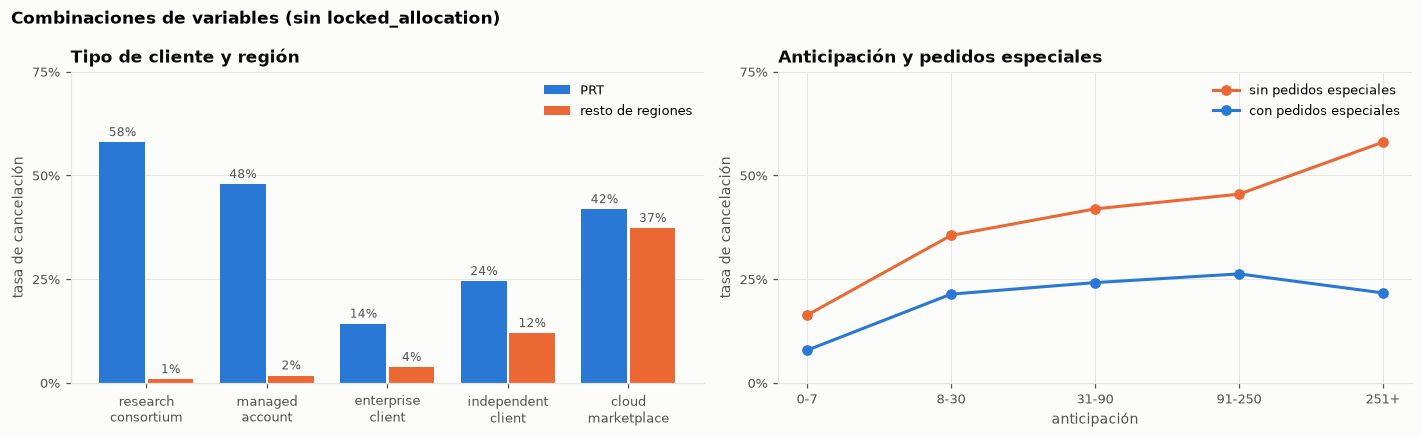

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
xx = np.arange(len(tipos))
axes[0].bar(xx - 0.2, t1[("mean", "PRT")], width=0.38, color=C_TODO, label="PRT")
axes[0].bar(xx + 0.2, t1[("mean", "resto")], width=0.38, color=C_SINL, label="resto de regiones")
for i, t in enumerate(tipos):
    axes[0].text(i - 0.2, t1.loc[t, ("mean", "PRT")] + 0.015, f"{t1.loc[t, ('mean', 'PRT')]:.0%}", ha="center", fontsize=8, color=INK2)
    axes[0].text(i + 0.2, t1.loc[t, ("mean", "resto")] + 0.015, f"{t1.loc[t, ('mean', 'resto')]:.0%}", ha="center", fontsize=8, color=INK2)
axes[0].set_xticks(xx, [t.replace("_", "\n") for t in tipos]); axes[0].grid(axis="x", visible=False); axes[0].legend()
axes[0].set_title("Tipo de cliente y región")
axes[1].plot(t2.index.astype(str), t2["sin pedidos"], color=C_SINL, lw=2, marker="o", label="sin pedidos especiales")
axes[1].plot(t2.index.astype(str), t2["con pedidos"], color=C_TODO, lw=2, marker="o", label="con pedidos especiales")
axes[1].set_xlabel("anticipación"); axes[1].legend(); axes[1].set_title("Anticipación y pedidos especiales")
for ax in axes:
    ax.set_ylim(0, 0.75); ax.set_yticks(np.arange(0, 0.76, 0.25), ["0%", "25%", "50%", "75%"]); ax.set_ylabel("tasa de cancelación")
fig.suptitle("Combinaciones de variables (sin locked_allocation)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "07_interacciones"); plt.show()

**Qué muestran los datos**
- **Redundancia:** solo los pares ya conocidos (los totales con sus partes, trabajos previos con cliente recurrente, costo con `high_value_client`). Ninguna otra correlación entre numéricas pasa de 0,35.
- **Categóricas asociadas:** tipo de cliente con canal (0,81) y con tener organización (0,83). Cada agente principal trabaja con un solo tipo de cliente.
- **El costo es una tarifa:** depende del tipo de GPU (de 4,7 a 11,3), del mes (de 3,95 a 6,0), de la cantidad de procesos y del tipo de cliente.
- **Región y tipo de cliente:** en `research_consortium` la cancelación es 58% en `PRT` y 1% en el resto; en `managed_account`, 48% y 2%. En `cloud_marketplace` la región casi no importa (42% y 37%).
- **Anticipación y pedidos especiales:** sin pedidos, la cancelación sube de 16% a 58% con la anticipación; con pedidos se estanca cerca de 25%.

**Interpretación**
- La cancelación depende de perfiles: quién reserva (tipo, región, agente) combinado con cómo reserva (anticipación, pedidos).
- Un modelo que solo sume efectos por separado pierde estas combinaciones y queda subajustado. Los árboles las capturan solos.

**Decisiones**
- No se elimina ninguna variable por redundancia (para un modelo lineal, sí convendría sacar los totales y `high_value_client`).
- La columna que combina tipo de cliente con `PRT` no se agrega: queda como candidata. La elegimos mirando el objetivo y fija a mano una región que podría no estar en el test.
- Toda columna nueva entra solo si mejora la validación cruzada más que la variación entre folds.
- Un modelo lineal simple sirve de referencia: los modelos de árboles tienen que superarlo con margen.

---
## Paso 7 · Conclusiones

**Qué aprendimos del dataset**
1. El 16% de las reservas (`locked_allocation`) cancela el 99,8%. Son reservas en bloque, casi todas de `PRT`, y explican el 38% de los cancelados. La dificultad real está en el otro 84%, donde cancela el 30,6%.
2. Un tercio de las filas son copias exactas, porque no hay identificador de reserva y muchos clientes reservan en bloque.
3. Dos columnas revelan el resultado y quedan fuera. Una tercera, la GPU asignada, se registra tarde y se evalúa con y sin.
4. Las variables con señal propia son el agente, la anticipación, la región, el tipo de cliente, los pedidos especiales, las cancelaciones previas y las modificaciones.
5. Varias señales aparentes (espera en cola, pico de costo, `research_consortium`) eran efecto de los bloques.
6. Las relaciones no son rectas y dependen de combinaciones, sobre todo región con tipo de cliente.
7. Hay límites conocidos: los `no_show` parecen completados (hasta 1,3 puntos) y 52 grupos tienen entradas iguales con resultados distintos (0,26% de las filas).

**Qué implica para el modelado**
- **Fuga:** todo lo que se aprende de los datos (categorías frecuentes, tope del costo, codificación) va dentro del pipeline y se ajusta en cada fold.
- **Sobreajuste:** los folds agrupan filas con las mismas entradas; las categorías raras van a `otros`; ninguna columna nueva entra sin mejorar más que la variación entre folds.
- **Subajuste:** hace falta un modelo que capture relaciones no rectas y combinaciones; el modelo lineal queda como referencia.
- **Test desconocido:** no sabemos cómo es el test de la competencia. La evaluación se informa también por subgrupos (`PRT` y resto, por año, con y sin `locked_allocation`) y se suma una validación más dura, dejando afuera un año o una región.

**Pendiente para la etapa de modelado**
- Comparar con y sin `assigned_gpu_type`.
- Probar la columna candidata de tipo de cliente con `PRT`.
- Revisar qué tan sensible es el punto de corte si cambia la proporción de cancelados.